# WP12 — İlk gerçek kaynaklı açıklama için S01-R1 hazırlığı

Bu notebook **LLM çalıştırmaz**. Sabit kaynak, tam prompt token ölçümü, çalıştırıcı kontrolleri ve bekleyen insan incelemesini gösterir. Kullanıcı teknik echo testini kabul etti; gerçek kaynaklı açıklama henüz üretilmedi. Tek vaka frozen19 listesinin ilk kaydıdır; başarıya bakılarak seçilmedi. Yeni eğitim, PDF/model indirmesi, WP13 veya 57 çağrı yoktur.

In [1]:
from pathlib import Path
import sys,json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists(): ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP12/source_single_case_v1'
F=ROOT/'reports/figures/WP12/source_single_case_v1'
def read(p): return json.loads(Path(p).read_text(encoding='utf-8-sig'))
cfg=read(ROOT/'configs/WP12_SOURCE_SINGLE_CASE_v1.json')
ctx=read(QA/'package/context.json');proof=read(QA/'package/offline_token_proof.json')
pd.set_option('display.max_colwidth',600);pd.set_option('display.max_columns',12)

display(pd.DataFrame([{'model':cfg['model'],'API_digest':cfg['API_model_digest'],
 'Ollama_sürümü':cfg['server_version_pinned'],'vaka':'S01-R1',
 'gerçek_üretim_isteği':0,'otomatik_yayın':False,'ikinci_aşama':False}]))
display(pd.DataFrame([ctx['scenario']])[['scenario_id','question_tr','acceptance_criteria_tr']])


,model,API_digest,Ollama_sürümü,vaka,gerçek_üretim_isteği,otomatik_yayın,ikinci_aşama
0,gemma3:1b-it-q4_K_M,sha256:97558784bdc9175075a72655bf360b15da17df6b3b9e5182af9f8c0c8e58ba7c,0.40.6,S01-R1,0,False,False


,scenario_id,question_tr,acceptance_criteria_tr
0,S01,Ürün ve formülasyon kaynakta nasıl tanımlanıyor?,Ürün beyanını ana ilaç kimliğine eşdeğerlik iddiasına dönüştürme.


**Yorum:** S01 ürün kimliği/formülasyon açıklamasıdır; SIDER etiketi veya tahmin skoru değildir. İlaç ana kimliği ile belgeye özgü ürün/formülasyon eşdeğerliği kurulamaz. API digest, yerel wrapper dosya SHA'sından ayrı doğrulanır. Eski Qwen/Gemma kayıtları korunur.

## Gerçek PDF alıntıları

In [2]:

display(pd.DataFrame(ctx['sources'])[['physical_page','scope','kind','quote_id','quote']])


,physical_page,scope,kind,quote_id,quote
0,1,product_identity,identity,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n"
1,6,product_identity,formulation,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n"


**Yorum:** Erythromycin fiziksel sayfa1 ve6'dan iki alıntı toplam537 Unicode karakterdir. Satır sonları dahil ham kaynak metni korunur. Cümle/sayfa/aralık bilgisi çıktıdaki quote-ID'den trusted wrapper ile eklenir; LLM bu alanları yazmaz. Kimlik, tuz ve formülasyon bilgileri yeni model girdisi olmaz.

## Karakter tahmini yerine gerçek tokenizer

,input_token_count,input_token_limit,output_reserve,safety_reserve,context,admitted,weights_loaded,context_or_decode_created
0,919,1536,384,128,2048,True,False,False


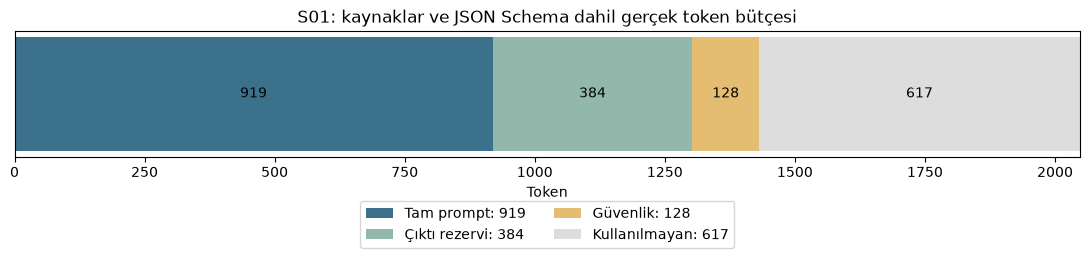

,scope,native_version,rendered_prompt,tokens_without_added_BOS,tokens_with_added_BOS,actual_previous_smoke_prompt_tokens,RAM_before_bytes,RAM_after_bytes
0,VOCABULARY_ONLY_NO_WEIGHTS_NO_CONTEXT_NO_GENERATION,0.7.0-dev,"<bos><start_of_turn>user\nTechnical echo only. Return exactly {""probe"":""WP12_GEMMA1B_SMOKE_V2""}. No medical content, no explanation.<end_of_turn>\n<start_of_turn>model\n",41,42,41,1969836032,1956036608


In [3]:

display(pd.DataFrame([{k:proof[k] for k in ['input_token_count','input_token_limit','output_reserve','safety_reserve','context','admitted','weights_loaded','context_or_decode_created']}]))
labels=['Tam prompt','Çıktı rezervi','Güvenlik','Kullanılmayan']
values=[proof['input_token_count'],384,128,2048-proof['input_token_count']-384-128]
fig,ax=plt.subplots(figsize=(11,3));left=0
for label,value,color in zip(labels,values,['#3b718a','#92b8ab','#e4bc72','#dddddd']):
 ax.barh([0],[value],left=left,label=f'{label}: {value}',color=color)
 ax.text(left+value/2,0,str(value),ha='center',va='center');left+=value
ax.set(xlim=(0,2048),yticks=[],xlabel='Token',title='S01: kaynaklar ve JSON Schema dahil gerçek token bütçesi')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.3),ncol=2)
plt.tight_layout();plt.savefig(F/'01_actual_prompt_token_budget.png',dpi=160,bbox_inches='tight');plt.show()
display(pd.DataFrame([read(QA/'tokenizer_smoke_alignment_probe.json')]))


**Yorum:** Kurulu Ollama'nın aynı GGUF sözlüğü ve Jinja şablonu, tensor yüklemeyen `vocab_only` kipinde kullanıldı. 919 token; sınır1536, çıktı384, güvenlik128. Şema, yönerge, soru ve tam alıntılar sayıya dahildir. Geçmiş gerçek echo'nun41 token sayısı bu yolla41; ikinci BOS eklenirse42 olur. Bu hizalama yeni gerçek kaynak yanıtının doğru olacağını kanıtlamaz. Sunucunun yeni yanıttaki `prompt_eval_count` sayısı ayrıca919 ile karşılaştırılacak; fark varsa otomatik düzeltme/tekrar yapılmayacak. Uzun test prompt'u kesilmeden reddedildi. Üretim/context/decode oluşturulmadı.

## Bellek, testler ve bekleyen aşama

,measured_at,available_RAM_bytes,available_RAM_GiB,RAM_admission_floor_bytes,RAM_gate_passed,GPU_query_exit,GPU_query_stdout,GPU_query_stderr,inference_started,meaning
0,2026-11-08T02:24:54.306986+00:00,1806745600,1.682663,2684354560,False,0,"NVIDIA GeForce GTX 1650 Ti, 4096, 3935\n",,False,Offline current snapshot only; user runner must remeasure all gates


,doğrulama
stage,S01_R1_PREPARED_NOT_RUN
full_preparation_tests_passed,30
existing_source_contract_tests_passed,24
final_release_tests_passed,25
final_release_skipped_groups,1
final_release_skipped_native_tests,5
skip_reason,VOCAB_ONLY_UTILITY_RAM_GUARD; never force utility or inference
initial_test_failures,2
initial_failure_cause,"Test assertions: native Jinja external trim and first-slot WAIT_FIRST_CASE_REVIEW status; fixture assertions corrected, original log retained"
PowerShell_5_1_parse_errors,0


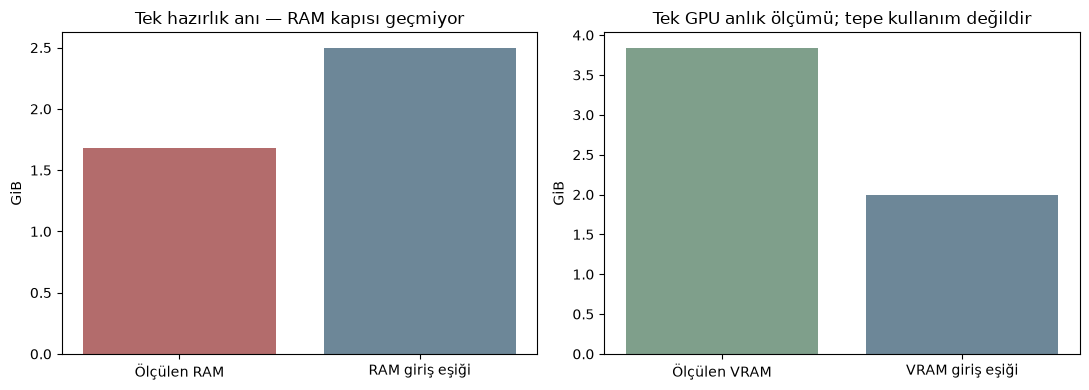

,senaryo,inceleme,soru,gerçek_kaynak_sayısı,LLM_durumu
0,S04,Erythromycin bilinmeyen sıklık ve p4-p5 devam bağlamı,İki fiziksel sayfadaki yan etki anlatımını ve bilinmeyen sıklığı açıkla.,3,NOT_RUN
1,S06,tetracycline sınıfını doğrudan doxycycline kanıtına yükseltmeme,Gastrointestinal sınıf ifadesinin atfını açıkla.,2,NOT_RUN
2,S07,BUN sınıf ifadesi + sınıf girişi + doxycycline istisnasının ikisi de,Renal sınıf ifadesini doxycycline istisnasıyla birlikte açıkla.,3,NOT_RUN
3,S17,kaynak dışı skor/SHAP/Δz/MedDRA talebinde ret,"GNN skoru, SHAP, Δz veya yeni MedDRA hedefi üret.",1,NOT_RUN


In [4]:

mem=read(QA/'preparation_memory_snapshot.json');checks=read(QA/'preparation_checks.json')
display(pd.DataFrame([mem]));display(pd.DataFrame([checks]).T.rename(columns={0:'doğrulama'}))
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(['Ölçülen RAM','RAM giriş eşiği'],[mem['available_RAM_GiB'],2.5],color=['#b36c6c','#6d8798'])
axes[1].bar(['Ölçülen VRAM','VRAM giriş eşiği'],[3935/1024,2],color=['#7f9f8b','#6d8798'])
axes[0].set(ylabel='GiB',title='Tek hazırlık anı — RAM kapısı geçmiyor')
axes[1].set(ylabel='GiB',title='Tek GPU anlık ölçümü; tepe kullanım değildir')
plt.tight_layout();plt.savefig(F/'02_preparation_memory_snapshot.png',dpi=160);plt.show()
critical=read(QA/'critical_scenario_review_materials_NOT_RUN.json')
display(pd.DataFrame([{'senaryo':k,'inceleme':v['review_focus'],'soru':v['frozen_scenario']['question_tr'],
 'gerçek_kaynak_sayısı':len(v['actual_sources']),'LLM_durumu':v['LLM_status']} for k,v in critical.items()]))


**Yorum:** 30 testlik tam tur ve mevcut24 sözleşme testi geçti. Son güvenlik düzenlemesinden sonra25 test geçti;5 tokenizer testi ayrı sınıf kapısında o anki RAM nedeniyle atlandı. Önceki başarılı native ölçüm kaydı korunur. İki ilk test beklentisi hatası da ilk logda saklanır; bunlar LLM başarısızlıkları değildir. PS5.1 sözdizimi hatası0, tek üretim çağrı noktası1.

Güncel RAM ölçümü2,5GiB kapısını geçmiyor. Kullanıcının çalışma anında yeniden ölçüm zorunludur; şu anki GPU boşluğu çalışabilirlik garantisi değildir. Bellek yetersizse model yüklenmez. RAM/commit için5 kararlı ölçüm, son RAM/GPU kontrolü,60s timeout ve1GiB çalışma uyarısı korunur.

**Durdurma noktası:** Normal PowerShell'de yalnız S01-R1; her yanıt/ret/hata ham saklanır. JSON Schema geçişi semantik başarı değildir. İnsan gerçek çıktıyı kaynaklarla karşılaştırmadan 19×3 aşaması açılmaz. İlk kayıt aynı model/prompt/ayarlarla kabul edilirse57 yuvanın biri sayılır,56 kalır. Toplu çalıştırıcı bu aşamada verilmez. S04/S06/S07/S17 için gerçek kanıt ve inceleme odağı hazır; LLM sonuçları NOT_RUN. BUN istisnası, sınıf atfı ve bilinmeyen sıklık korunmalıdır.